# SME · Entrega de Python
## Uso de las funciones con el dataset Iris

Este notebook documenta exclusivamente el paquete Python `sme`. Incluye código,
resultados y explicaciones de todas sus funciones públicas. Las implementaciones de
discretización, métricas, transformaciones, selección, correlación e información mutua
son propias. pandas se utiliza para estructuras de datos y matplotlib para visualizar.

### Instalación y datos

Desde el directorio `SME-py`, instala el paquete y las herramientas del notebook:

```bash
python3 -m pip install '.[notebook]'
```

Abre `notebooks/entrega.ipynb` con un kernel Python que tenga instalado el paquete.
El archivo local `data/iris.csv` contiene los valores originales de Iris. No se descargan
datos durante la ejecución ni se generan observaciones artificiales.

Iris recoge cuatro medidas de flores en centímetros y su especie. El CSV conserva los
nombres originales `Sepal.Length`, `Sepal.Width`, `Petal.Length`, `Petal.Width` y `Species`.
Fuente: [documentación original de iris](https://stat.ethz.ch/R-manual/R-devel/library/datasets/html/iris.html).

In [1]:
from pathlib import Path
import tempfile

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sme

# Buscar los datos desde SME-py/ o desde notebooks/.
candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next(path for path in candidates if (path / "data" / "iris.csv").is_file())
iris = pd.read_csv(ROOT / "data" / "iris.csv")

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
display(iris.head())
print("Dimensiones:", iris.shape)
display(iris["Species"].value_counts().sort_index().rename("observaciones"))

Dimensiones: (150, 5)


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Species
setosa        50
versicolor    50
virginica     50
Name: observaciones, dtype: int64

## 1. Preparar el análisis supervisado

El AUC implementado requiere exactamente dos clases. Por eso se utiliza un subconjunto
real de Iris con **versicolor y virginica**, conservando todas sus observaciones y las
medidas originales. `virginica` será la clase positiva. Se obtienen 100 filas; no se
recodifican especies ni se inventan valores.

Las funciones reconocen como numéricas las columnas de tipo numérico; texto, categorías
y booleanas se consideran categóricas. Los códigos numéricos que representen categorías
se pueden declarar mediante `categorical`. La clase se indica con `class_column` en las
funciones de dataset y se excluye de las métricas de atributos.

Los estadísticos omiten ausentes; las operaciones por pares usan observaciones completas.
Las transformaciones conservan los ausentes y el índice. Iris no contiene ausentes, por
lo que los ejemplos no alteran artificialmente sus datos para introducirlos.

In [2]:
iris_binary = iris.loc[iris["Species"].isin(["versicolor", "virginica"])].copy()
positive = "virginica"
display(iris_binary["Species"].value_counts().sort_index().rename("observaciones"))

Species
versicolor    50
virginica     50
Name: observaciones, dtype: int64

## 2. Discretización de un atributo y de un dataset

`discretize_ew(x, num_bins, exclude=())` divide el rango en intervalos de igual anchura.
Sus cortes son `mínimo + j·(máximo−mínimo)/k`. Conserva distancias en la escala original,
pero no busca grupos del mismo tamaño.

`discretize_ef(x, num_bins, exclude=())` elige cortes sobre las posiciones ordenadas
próximas a `n·j/k`. Conserva juntos los valores iguales, por lo que los empates pueden
producir frecuencias desiguales o menos intervalos que los solicitados.

Ambas funciones reciben un vector, Series o DataFrame y un entero positivo de intervalos.
Devuelven una lista, Series o copia del DataFrame, respectivamente. En datasets solo
cambian columnas numéricas no excluidas; `Species` permanece como categoría. Un valor
igual al corte se asigna al intervalo inferior. Las constantes generan `I1`.

In [3]:
x = iris["Petal.Length"]
width = sme.discretize_ew(x, 3)
frequency = sme.discretize_ef(x, 3)
display(pd.DataFrame({"Petal.Length": x, "igual_anchura": width,
                      "igual_frecuencia": frequency}).head(10))
display(pd.DataFrame({"igual_anchura": width.value_counts(),
                      "igual_frecuencia": frequency.value_counts()}).sort_index())

iris_ew = sme.discretize_ew(iris, 3, exclude=["Species"])
iris_ef = sme.discretize_ef(iris, 3, exclude=["Species"])
display(iris_ew.head())
display(iris_ef.head())

,Petal.Length,igual_anchura,igual_frecuencia
0,1.4,I1,I1
1,1.4,I1,I1
2,1.3,I1,I1
3,1.5,I1,I1
4,1.4,I1,I1
5,1.7,I1,I1
6,1.4,I1,I1
7,1.5,I1,I1
8,1.4,I1,I1
9,1.5,I1,I1


,igual_anchura,igual_frecuencia
Petal.Length,,
I1,50,50
I2,54,54
I3,46,46


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,I1,I2,I1,I1,setosa
1,I1,I2,I1,I1,setosa
2,I1,I2,I1,I1,setosa
3,I1,I2,I1,I1,setosa
4,I1,I2,I1,I1,setosa


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,I1,I3,I1,I1,setosa
1,I1,I2,I1,I1,setosa
2,I1,I2,I1,I1,setosa
3,I1,I2,I1,I1,setosa
4,I1,I3,I1,I1,setosa


### Cortes explícitos y búsqueda de intervalos

`discretize(x, cut_points, label_prefix="I")` devuelve etiquetas para cortes propios;
ordena y elimina cortes repetidos. Aquí se reutilizan el mínimo y máximo observados de
la longitud del pétalo para obtener los cortes de igual anchura. `find_range(value,
cut_points)` devuelve el índice del intervalo desde 1 mediante búsqueda binaria; cuando
se utiliza directamente, los cortes deben estar ordenados y no contener ausentes.

In [4]:
low, high = min(x), max(x)
cuts = [low + (high - low) * j / 3 for j in (1, 2)]
print("Cortes:", cuts)
print("Primeras etiquetas:", sme.discretize(x, cuts, label_prefix="P")[:6])
print("Intervalo de la primera medida:", sme.find_range(x.iloc[0], cuts))

Cortes: [2.966666666666667, 4.933333333333334]
Primeras etiquetas: ['P1', 'P1', 'P1', 'P1', 'P1', 'P1']
Intervalo de la primera medida: 1


## 3. Métricas individuales y reconocimiento del tipo

`mean`, `variance` y `std_dev` reciben un vector numérico y devuelven un escalar.
La media es `sum(x)/n`, la varianza muestral usa `sum((x−media)²)/(n−1)` y la desviación
es su raíz. Con menos de dos observaciones, la varianza y desviación son `NaN`.

`entropy` recibe categorías y calcula `−sum(p·log₂(p))` en bits. Es cero para una
categoría constante. Las categorías de la discretización también pueden evaluarse con
esta función: la transformación es explícita y sus etiquetas proceden de Iris.

`attribute_metrics` devuelve una tabla con una fila por atributo: nombre, tipo, número
de valores observados, varianza, entropía y AUC. En numéricas calcula varianza y, si hay
clase binaria, AUC; en categóricas calcula entropía. Las métricas no aplicables son `NaN`.

In [5]:
print("Media del pétalo:", sme.mean(x))
print("Varianza muestral:", sme.variance(x))
print("Desviación muestral:", sme.std_dev(x))
print("Entropía de Species (bits):", sme.entropy(iris["Species"]))
print("Entropía del pétalo discretizado (bits):", sme.entropy(iris_ef["Petal.Length"]))

# No supervisado: permite las tres especies; no solicita AUC.
display(sme.attribute_metrics(iris))
# Supervisado: clase binaria explícita.
metrics = sme.attribute_metrics(iris_binary, class_column="Species", positive=positive)
display(metrics)

Media del pétalo: 3.7580000000000005
Varianza muestral: 3.1162778523489933
Desviación muestral: 1.7652982332594664
Entropía de Species (bits): 1.584962500721156
Entropía del pétalo discretizado (bits): 1.58188145993464


,attribute,type,n,variance,entropy,auc
0,Sepal.Length,numeric,150,0.6857,NaN,NaN
1,Sepal.Width,numeric,150,0.1900,NaN,NaN
2,Petal.Length,numeric,150,3.1163,NaN,NaN
3,Petal.Width,numeric,150,0.5810,NaN,NaN
4,Species,categorical,150,NaN,1.585,NaN


,attribute,type,n,variance,entropy,auc
0,Sepal.Length,numeric,100,0.4393,NaN,0.7896
1,Sepal.Width,numeric,100,0.1107,NaN,0.6636
2,Petal.Length,numeric,100,0.6816,NaN,0.9822
3,Petal.Width,numeric,100,0.1804,NaN,0.9804


### Entropía cruzada e información mutua

`cross_entropy(x, y)` compara las distribuciones de dos muestras categóricas:
`H(P,Q)=−sum(p·log₂(q))`. No exige igual longitud; alinea por etiqueta y devuelve infinito
si una categoría de P no está observada en Q. Se conserva de la implementación original.
Con una distribución comparada consigo misma, coincide con su entropía.

`mutual_info(x, y)` exige vectores emparejados y calcula
`sum(p(x,y)·log₂(p(x,y)/(p(x)·p(y))))` a partir de frecuencias conjuntas. No utiliza
entropía cruzada. Se expresa en bits y no está limitada a uno. Aquí relaciona la especie
con el intervalo de longitud del pétalo y también muestra la relación de la especie
consigo misma, que coincide con su entropía.

In [6]:
print("Entropía cruzada Species/Species:", sme.cross_entropy(iris["Species"], iris["Species"]))
print("MI Species/Species:", sme.mutual_info(iris["Species"], iris["Species"]))
print("MI pétalo discretizado/Species:",
      sme.mutual_info(iris_ef["Petal.Length"], iris["Species"]))

Entropía cruzada Species/Species: 1.584962500721156
MI Species/Species: 1.5849625007211559
MI pétalo discretizado/Species: 1.3246637751447135


## 4. Normalización y estandarización

`normalize(x, exclude=())` calcula `(x−mínimo)/(máximo−mínimo)` y lleva el rango observado
a `[0,1]`. `standardize(x, exclude=())` calcula `(x−media)/desviación_muestral`: centra y
ajusta la escala, sin imponer ese rango. Ambas admiten vectores, Series y DataFrames y
devuelven una nueva estructura. En datasets solo modifican columnas numéricas.

Una constante, o una sola observación al estandarizar, produce ceros. No se modifican
las medidas originales de `iris`: se generan versiones transformadas por las funciones.

In [7]:
display(pd.DataFrame({"original": x, "normalizada": sme.normalize(x),
                      "estandarizada": sme.standardize(x)}).head())
normalized = sme.normalize(iris, exclude=["Species"])
standardized = sme.standardize(iris, exclude=["Species"])
display(normalized.head())
display(standardized.head())
print("Media del pétalo estandarizado:", sme.mean(standardized["Petal.Length"]))
print("Desviación del pétalo estandarizado:", sme.std_dev(standardized["Petal.Length"]))

Media del pétalo estandarizado: -2.749652357654971e-16
Desviación del pétalo estandarizado: 0.9999999999999999


,original,normalizada,estandarizada
0,1.4,0.0678,-1.3358
1,1.4,0.0678,-1.3358
2,1.3,0.0508,-1.3924
3,1.5,0.0847,-1.2791
4,1.4,0.0678,-1.3358


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,0.2222,0.6250,0.0678,0.0417,setosa
1,0.1667,0.4167,0.0678,0.0417,setosa
2,0.1111,0.5000,0.0508,0.0417,setosa
3,0.0833,0.4583,0.0847,0.0417,setosa
4,0.1944,0.6667,0.0678,0.0417,setosa


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,-0.8977,1.0156,-1.3358,-1.3111,setosa
1,-1.1392,-0.1315,-1.3358,-1.3111,setosa
2,-1.3807,0.3273,-1.3924,-1.3111,setosa
3,-1.5015,0.0979,-1.2791,-1.3111,setosa
4,-1.0184,1.2450,-1.3358,-1.3111,setosa


## 5. Selección por umbrales

`filter_features` recibe el dataset y umbrales mínimos inclusivos: una columna debe
cumplir todas las condiciones que correspondan a su tipo. `min_variance` y `min_auc`
se aplican a numéricas; `min_entropy`, a categóricas. Omitir un umbral no impone esa
condición. Una métrica indefinida no supera un umbral solicitado.

La salida es una copia con las columnas aceptadas en su orden original y conserva la
clase. Filtrar por AUC requiere clase binaria y su dirección original: el algoritmo no
invierte automáticamente un atributo con AUC bajo.

Los valores 0.1, 0.8 y 1.5 son **criterios de ejemplo**, no parámetros aprendidos ni
resultados asumidos. Se muestra la salida real. El segundo caso discretiza primero
las medidas de Iris y filtra categorías por entropía, sin solicitar AUC.

In [8]:
selected = sme.filter_features(iris_binary, min_variance=0.1, min_auc=0.8,
                               class_column="Species", positive=positive)
print("Columnas conservadas:", list(selected.columns))
display(selected.head())

selected_discrete = sme.filter_features(iris_ef, min_entropy=1.5)
print("Columnas discretas conservadas:", list(selected_discrete.columns))
display(selected_discrete.head())

Columnas conservadas: ['Petal.Length', 'Petal.Width', 'Species']
Columnas discretas conservadas: ['Sepal.Length', 'Sepal.Width', 'Petal.Length', 'Petal.Width', 'Species']


,Petal.Length,Petal.Width,Species
50,4.7,1.4,versicolor
51,4.5,1.5,versicolor
52,4.9,1.5,versicolor
53,4.0,1.3,versicolor
54,4.6,1.5,versicolor


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,I1,I3,I1,I1,setosa
1,I1,I2,I1,I1,setosa
2,I1,I2,I1,I1,setosa
3,I1,I2,I1,I1,setosa
4,I1,I3,I1,I1,setosa


## 6. Correlación y matriz de asociaciones

`pearson(x, y)` recibe dos vectores numéricos emparejados y devuelve la correlación
lineal en `[-1,1]`. Utiliza los productos de las desviaciones; no llama a implementaciones
de correlación de otras bibliotecas. Es indefinida con constantes o menos de dos pares.

`association_matrix(df, categorical=(), num_bins=5)` devuelve un diccionario con los
DataFrames simétricos `values` y `methods`. Dos numéricas usan Pearson; dos categóricas,
información mutua. En un par mixto discretiza la numérica por igual frecuencia sobre
los pares completos y calcula información mutua (`mi_discretized`). El número de
intervalos influye en esta última asociación y queda explícito.

In [9]:
print("Pearson entre longitud y anchura del pétalo:",
      sme.pearson(iris["Petal.Length"], iris["Petal.Width"]))
associations = sme.association_matrix(iris, num_bins=3)
display(associations["values"])
display(associations["methods"])
# Una matriz completamente categórica utiliza solo información mutua.
discrete_associations = sme.association_matrix(iris_ef, num_bins=3)
display(discrete_associations["values"])

Pearson entre longitud y anchura del pétalo: 0.962865431402796


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
Sepal.Length,1.0000,-0.1176,0.8718,0.8179,0.6470
Sepal.Width,-0.1176,1.0000,-0.4284,-0.3661,0.3571
Petal.Length,0.8718,-0.4284,1.0000,0.9629,1.3247
Petal.Width,0.8179,-0.3661,0.9629,1.0000,1.3694
Species,0.6470,0.3571,1.3247,1.3694,1.5850


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
Sepal.Length,pearson,pearson,pearson,pearson,mi_discretized
Sepal.Width,pearson,pearson,pearson,pearson,mi_discretized
Petal.Length,pearson,pearson,pearson,pearson,mi_discretized
Petal.Width,pearson,pearson,pearson,pearson,mi_discretized
Species,mi_discretized,mi_discretized,mi_discretized,mi_discretized,mi


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
Sepal.Length,1.5747,0.2403,0.7122,0.6595,0.6470
Sepal.Width,0.2403,1.5755,0.3680,0.3781,0.3571
Petal.Length,0.7122,0.3680,1.5819,1.2318,1.3247
Petal.Width,0.6595,0.3781,1.2318,1.5842,1.3694
Species,0.6470,0.3571,1.3247,1.3694,1.5850


## 7. AUC, curva ROC y gráficos

`sme.auc(scores, classes, positive)` recibe puntuaciones numéricas y etiquetas binarias.
Un score alto predice la clase positiva. El AUC integra trapecios de la curva ROC; los
empates se incorporan juntos y equivalen a media victoria entre pares positivo/negativo.
No se entrena un clasificador: aquí las puntuaciones son directamente la longitud del
pétalo de cada flor observada. Un AUC de 0.5 corresponde a ausencia de capacidad de
ordenación; uno menor puede indicar relación inversa, que no se corrige automáticamente.

`roc_curve` devuelve umbrales, tasa de falsos positivos y tasa de verdaderos positivos.
`plot_roc` dibuja la curva y el AUC con matplotlib y devuelve los ejes (`Axes`).
`plot_association` recibe las asociaciones y devuelve figura y ejes. Separa Pearson y
MI porque sus unidades son distintas; el gris indica valores ausentes o el otro método.
Las figuras devueltas pueden guardarse mediante `figure.savefig(...)`.

AUC del pétalo para virginica: 0.9822


,threshold,fpr,tpr
0,inf,0.0,0.00
1,6.9,0.0,0.02
2,6.7,0.0,0.06
3,6.6,0.0,0.08
4,6.4,0.0,0.10


,threshold,fpr,tpr
30,3.7,0.88,1.0
31,3.6,0.90,1.0
32,3.5,0.94,1.0
33,3.3,0.98,1.0
34,3.0,1.00,1.0


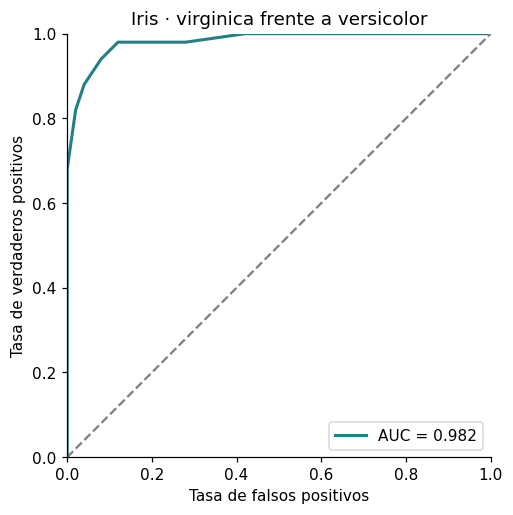

In [10]:
scores = iris_binary["Petal.Length"]
classes = iris_binary["Species"]
print("AUC del pétalo para virginica:", sme.auc(scores, classes, positive=positive))
roc = sme.roc_curve(scores, classes, positive=positive)
display(roc.head())
display(roc.tail())
ax = sme.plot_roc(scores, classes, positive=positive,
                  title="Iris · virginica frente a versicolor")
plt.show()

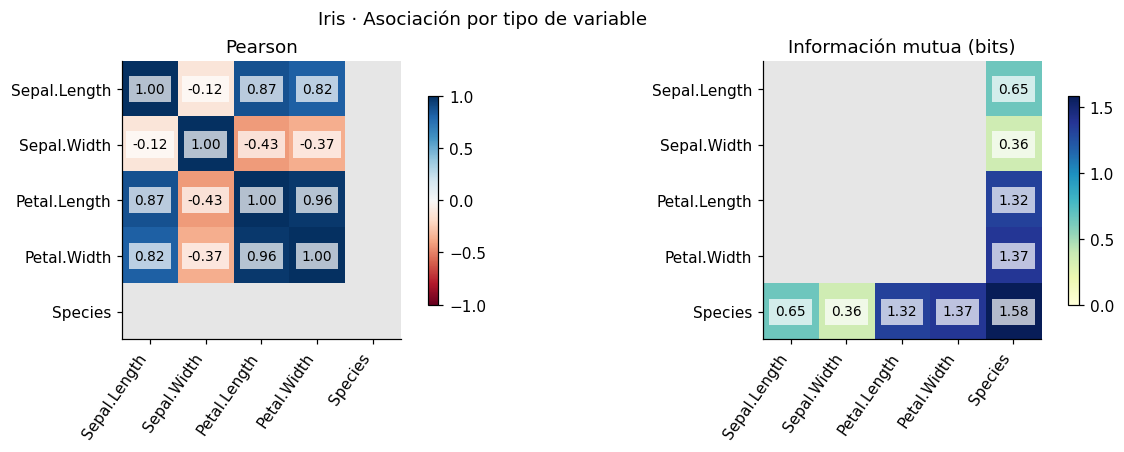

In [11]:
fig, axes = sme.plot_association(associations, title="Iris · Asociación por tipo de variable")
plt.show()

## 8. Objeto Dataset y lectura/escritura

`Dataset(data, class_column=None, positive=None, categorical=())` conserva una copia del
DataFrame y sus metadatos. `data` devuelve otra copia; `class_column`, `positive` y
`categorical` permiten consultar la configuración. Las transformaciones devuelven otro
Dataset y protegen automáticamente la clase y las categóricas declaradas.

`metrics()`, `filter()` y `associations()` reutilizan los metadatos. Los métodos
`normalize()`, `standardize()`, `discretize_ew()` y `discretize_ef()` reutilizan las
implementaciones anteriores; no incorporan algoritmos externos.

In [12]:
ds = sme.Dataset(iris_binary, class_column="Species", positive=positive)
print(ds)
print("Clase:", ds.class_column, "Positiva:", ds.positive, "Categóricas declaradas:", ds.categorical)
display(ds.data.head())
display(ds.metrics())
display(ds.normalize().data.head())
display(ds.standardize().data.head())
display(ds.discretize_ew(3).data.head())
display(ds.discretize_ef(3).data.head())
print("Filtrado:", list(ds.filter(min_auc=0.8).data.columns))
display(ds.associations(num_bins=3)["values"])

Dataset(100 filas, 5 columnas, class_column='Species')
Clase: Species Positiva: virginica Categóricas declaradas: ()
Filtrado: ['Petal.Length', 'Petal.Width', 'Species']


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
50,7.0,3.2,4.7,1.4,versicolor
51,6.4,3.2,4.5,1.5,versicolor
52,6.9,3.1,4.9,1.5,versicolor
53,5.5,2.3,4.0,1.3,versicolor
54,6.5,2.8,4.6,1.5,versicolor


,attribute,type,n,variance,entropy,auc
0,Sepal.Length,numeric,100,0.4393,NaN,0.7896
1,Sepal.Width,numeric,100,0.1107,NaN,0.6636
2,Petal.Length,numeric,100,0.6816,NaN,0.9822
3,Petal.Width,numeric,100,0.1804,NaN,0.9804


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
50,0.7000,0.6667,0.4359,0.2667,versicolor
51,0.5000,0.6667,0.3846,0.3333,versicolor
52,0.6667,0.6111,0.4872,0.3333,versicolor
53,0.2000,0.1667,0.2564,0.2000,versicolor
54,0.5333,0.4444,0.4103,0.3333,versicolor


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
50,1.1134,0.9857,-0.2495,-0.6498,versicolor
51,0.2082,0.9857,-0.4918,-0.4143,versicolor
52,0.9625,0.6852,-0.0073,-0.4143,versicolor
53,-1.1496,-1.7190,-1.0974,-0.8852,versicolor
54,0.3591,-0.2164,-0.3706,-0.4143,versicolor


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
50,I3,I2,I2,I1,versicolor
51,I2,I2,I2,I1,versicolor
52,I2,I2,I2,I1,versicolor
53,I1,I1,I1,I1,versicolor
54,I2,I2,I2,I1,versicolor


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
50,I3,I3,I2,I1,versicolor
51,I2,I3,I1,I2,versicolor
52,I3,I3,I2,I2,versicolor
53,I1,I1,I1,I1,versicolor
54,I2,I1,I2,I2,versicolor


,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
Sepal.Length,1.0000,0.5539,0.8285,0.5937,0.1379
Sepal.Width,0.5539,1.0000,0.5198,0.5662,0.0342
Petal.Length,0.8285,0.5198,1.0000,0.8233,0.6439
Petal.Width,0.5937,0.5662,0.8233,1.0000,0.6341
Species,0.1379,0.0342,0.6439,0.6341,1.0000


`to_csv(path)` guarda los valores sin índice y devuelve la ruta.
`Dataset.read_csv(path, ...)` lee los datos y construye el objeto. CSV no guarda los
metadatos, por lo que se especifican de nuevo al leer; `dtype` puede controlar los tipos.
El ejemplo usa un archivo temporal y copia únicamente observaciones de Iris.

In [13]:
with tempfile.TemporaryDirectory(prefix="sme-iris-") as directory:
    path = Path(directory) / "iris_binary.csv"
    ds.to_csv(path)
    loaded = sme.Dataset.read_csv(path, class_column="Species", positive=positive)
    print(loaded)
    display(loaded.metrics())

Dataset(100 filas, 5 columnas, class_column='Species')


,attribute,type,n,variance,entropy,auc
0,Sepal.Length,numeric,100,0.4393,NaN,0.7896
1,Sepal.Width,numeric,100,0.1107,NaN,0.6636
2,Petal.Length,numeric,100,0.6816,NaN,0.9822
3,Petal.Width,numeric,100,0.1804,NaN,0.9804


## 9. Referencia de la interfaz pública

Todas las funciones siguientes se han utilizado en este notebook. Las entradas, salidas
precisas y los criterios especiales también están documentados en sus docstrings,
consultables con `help(sme.nombre)`.

| Función | Entrada principal | Salida |
|:--|:--|:--|
| `discretize_ew`, `discretize_ef` | vector/Series/DataFrame, intervalos, exclusiones | etiquetas o dataset |
| `discretize` | vector, cortes, prefijo | lista de etiquetas |
| `find_range` | escalar, cortes ordenados | índice desde 1 |
| `mean`, `variance`, `std_dev` | vector numérico | escalar |
| `entropy` | categorías | bits |
| `cross_entropy` | dos muestras categóricas | bits |
| `mutual_info` | categorías emparejadas | bits |
| `attribute_metrics` | dataset, clase opcional, positiva, categóricas | tabla de métricas |
| `normalize`, `standardize` | vector/Series/DataFrame, exclusiones | datos transformados |
| `filter_features` | dataset, umbrales, clase y tipos | dataset seleccionado |
| `pearson` | vectores numéricos emparejados | correlación |
| `association_matrix` | dataset, tipos, intervalos mixtos | valores y métodos |
| `auc`, `roc_curve` | scores, clases binarias, positiva | área / tabla ROC |
| `plot_roc` | scores, clase binaria, positiva, ejes opcionales | ejes matplotlib |
| `plot_association` | asociaciones | figura y ejes |
| `Dataset` | DataFrame y metadatos | objeto de gestión |

### Reproducir esta entrega

Desde `SME-py`, con el paquete instalado en el mismo entorno que Jupyter:

```bash
jupyter nbconvert --to notebook --execute --inplace notebooks/entrega.ipynb
jupyter nbconvert --to html --embed-images notebooks/entrega.ipynb
```

`entrega.ipynb` es el documento editable y `entrega.html` es su versión de lectura.
Ambos pertenecen a la entrega de Python. La construcción del paquete con setuptools
se describe en `README.md` y su configuración está en `setup.py`.